In [1]:
import numpy as np
import matplotlib.pyplot as plt

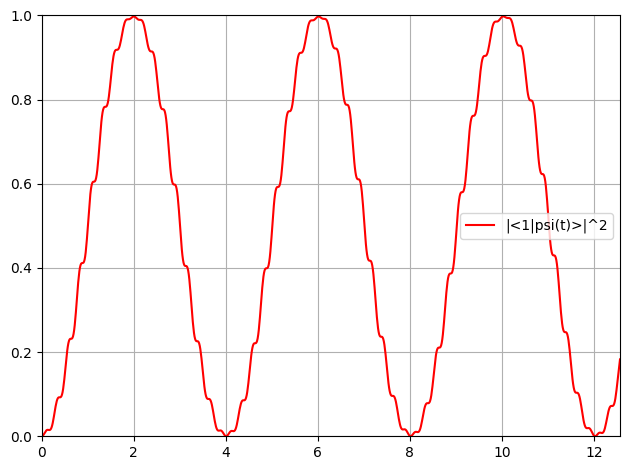

In [85]:
#Defining the time dependent perturbation
def V_t(mu,t,omega=1):
    return mu * np.exp(1j*omega*t) + np.conj(mu.T) * np.exp(-1j*omega*t)

sigma_x = np.array([[0,1],[1,0]], dtype = complex)
sigma_z = np.array([[1,0],[0,-1]], dtype = complex)

psi0 = np.array([1,0], dtype = complex)
ket1 = np.array([0,1], dtype = complex)
N = 1000
T = 4*np.pi
t = np.linspace(0,T,N)
psi = []
psi.append(psi0)

delta = 2 * np.pi          # Energy splitting (H0 scale)
omega = 2*delta             # Driving frequency
Omega = 0.5*np.pi 

H0 = sigma_z*delta
mu = (Omega / 2.0) * sigma_x
dt = t[1]-t[0]
for time in t:
    H_t = H0 + V_t(mu, time, omega)
    psi_next = psi[-1] + dt*(-1j)*(H_t)@psi[-1]
    psi.append(psi_next/np.linalg.norm(psi_next))
for i in range(len(psi)):
    psi[i] = abs(ket1@psi[i])**2
plt.plot(t,psi[:N], color = 'red', label = '|<1|psi(t)>|^2')
plt.ylim(0,1)
plt.xlim(0,T)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()